# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [ ]:
# Part 1: Scanner storage and rendering cost

nx, ny, nz = 512, 512, 300
bytes_per_voxel = 2  # 16-bit intensity

voxel_count = nx * ny * nz
storage_bytes = voxel_count * bytes_per_voxel

print(f"Voxels per scan: {voxel_count:,}")
print(f"Raw storage: {storage_bytes:,} bytes")
print(f"Raw storage: {storage_bytes / 1e6:.2f} MB")
print(f"Raw storage: {storage_bytes / (1024**2):.2f} MiB")

upsample = 2
resampled_voxels = (nx * upsample) * (ny * upsample) * (nz * upsample)

print(f"Resampled samples: {resampled_voxels:,}")
print(f"Samples per ray along x: {nx * upsample}")
print(f"Samples per ray along y: {ny * upsample}")
print(f"Samples per ray along z: {nz * upsample}")

Voxels per scan: 78,643,200
Raw storage: 157,286,400 bytes
Raw storage: 157.29 MB
Raw storage: 150.00 MiB
Resampled samples: 629,145,600
Samples per ray along x: 1024
Samples per ray along y: 1024
Samples per ray along z: 600


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_If the software ignores anisotropic voxel spacing, two things would go wrong:

1. Anatomical distortion: The coronal and sagittal views would appear stretched or compressed because the voxel dimensions are unequal (0.5 × 0.5 × 1.0 mm). Structures would not have their correct proportions, potentially misleading the radiologist.

2. Incorrect spatial measurements: Distances, tumour dimensions, and anatomical positions would be inaccurate because the software would treat voxels as if they had equal physical dimensions instead of accounting for the different spacing along the z-axis.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centroid (z, y, x): (28, 40, 41)
Largest component voxels: 431


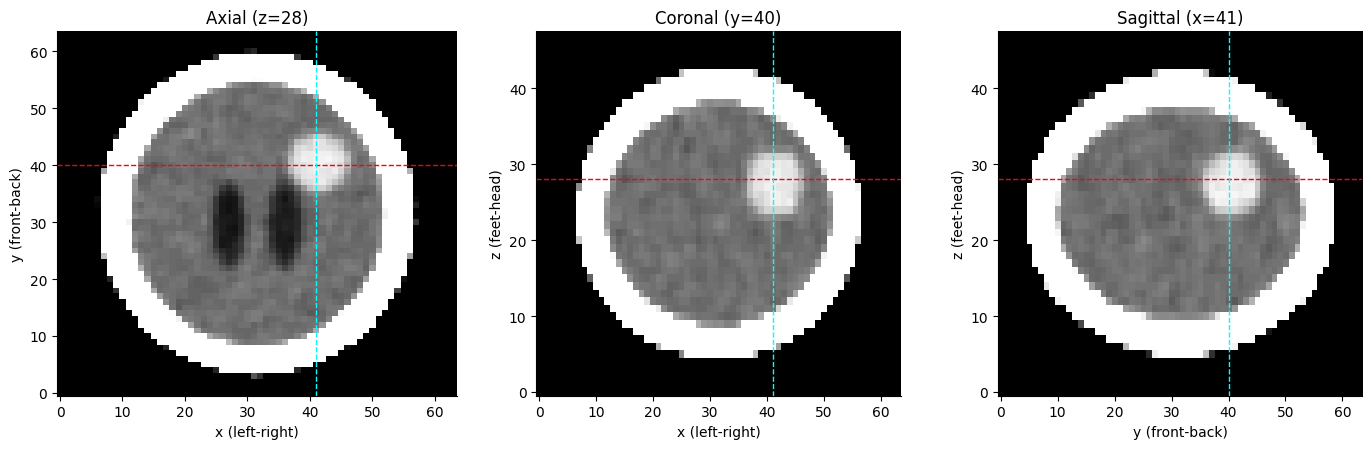

Ground-truth centroid (z, y, x): [27.5 40.5 41.5]
Detected centroid (z, y, x): [28 40 41]
Centroid distance: 2.92 mm


In [ ]:

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)


# TODO 1: Find candidate voxels without using labels
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)

candidates = (vol > 55) & (vol < 90) & inside


# TODO 2: Keep the largest connected component and find its centroid
components, num_components = ndimage.label(candidates)

if num_components == 0:
    raise ValueError("No lesion candidates found. Check the HU threshold and brain mask.")

component_sizes = np.bincount(components.ravel())
component_sizes[0] = 0  # Ignore background

largest_component = np.argmax(component_sizes)
lesion = components == largest_component

cz, cy, cx = (
    int(round(v))
    for v in ndimage.center_of_mass(lesion)
)

print(f"Lesion centroid (z, y, x): ({cz}, {cy}, {cx})")
print(f"Largest component voxels: {lesion.sum():,}")


# TODO 3: Plot axial, coronal and sagittal slices through the centroid
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial: fixed z, displayed as y vs x
axes[0].imshow(window(vol[cz, :, :], 80, 40),
               cmap="gray", origin="lower", aspect="auto")
axes[0].axhline(cy, color="red", linestyle="--", linewidth=1)
axes[0].axvline(cx, color="cyan", linestyle="--", linewidth=1)
axes[0].set_title(f"Axial (z={cz})")
axes[0].set_xlabel("x (left-right)")
axes[0].set_ylabel("y (front-back)")

# Coronal: fixed y, displayed as z vs x
axes[1].imshow(window(vol[:, cy, :], 80, 40),
               cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="red", linestyle="--", linewidth=1)
axes[1].axvline(cx, color="cyan", linestyle="--", linewidth=1)
axes[1].set_title(f"Coronal (y={cy})")
axes[1].set_xlabel("x (left-right)")
axes[1].set_ylabel("z (feet-head)")

# Sagittal: fixed x, displayed as z vs y
axes[2].imshow(window(vol[:, :, cx], 80, 40),
               cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="red", linestyle="--", linewidth=1)
axes[2].axvline(cy, color="cyan", linestyle="--", linewidth=1)
axes[2].set_title(f"Sagittal (x={cx})")
axes[2].set_xlabel("y (front-back)")
axes[2].set_ylabel("z (feet-head)")

plt.tight_layout()
plt.show()


# TODO 4: Evaluation only — compare with ground-truth tumour centroid
gt = labels == 5

if not np.any(gt):
    print("Ground-truth tumour label is empty; evaluation unavailable.")
else:
    gt_centroid = np.array(ndimage.center_of_mass(gt))
    detected_centroid = np.array([cz, cy, cx])

    voxel_diff = detected_centroid - gt_centroid
    distance_mm = np.sqrt(np.sum((voxel_diff * np.array(SPACING)) ** 2))

    print(f"Ground-truth centroid (z, y, x): {gt_centroid}")
    print(f"Detected centroid (z, y, x): {detected_centroid}")
    print(f"Centroid distance: {distance_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_ The erosion step removes voxels near the inner skull boundary to reduce false positives caused by the partial-volume effect, where a voxel contains a mixture of tissues and its measured HU value represents their combined intensity. These boundary voxels may have HU values between 55 and 90, overlapping with the tumour's intensity range. Since different tissues can have similar HU values, intensity thresholding alone cannot reliably distinguish them. Eroding the brain mask by three iterations reduces these boundary voxels, helping isolate the lesion more accurately.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold (HU),Voxel Count,Volume (mL),Dice
0,45,535,19.260,0.9289
1,50,464,16.704,0.9935
2,55,431,15.516,0.9631
3,60,350,12.600,0.8600
4,65,273,9.828,0.7408
5,70,170,6.120,0.5363


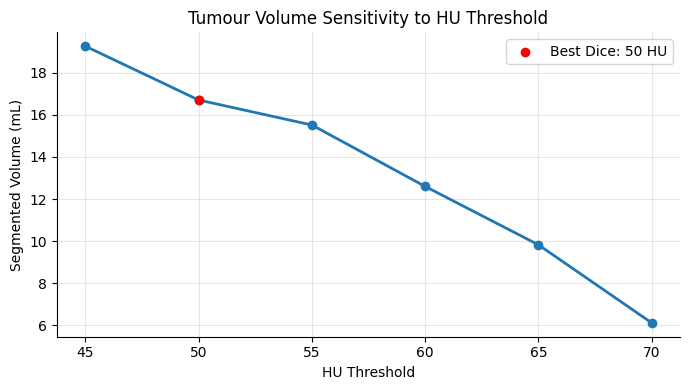

Best Dice threshold: 50 HU
Best Dice score: 0.9935
Volume range across thresholds: 6.120–19.260 mL
Volume variation: 13.140 mL
Surgeon-facing interpretation: report the threshold-dependent volume range and the threshold with the best Dice overlap.


In [ ]:

truth = labels == 5
rows = []

# TODO 1 & 2: Segment at each threshold and evaluate
thresholds = [45, 50, 55, 60, 65, 70]

for c in thresholds:
    # Threshold the CT without using ground-truth labels
    mask = vol > c

    # Connected component containing the detected lesion centre
    components, _ = ndimage.label(mask)

    centre_label = components[cz, cy, cx]

    if centre_label == 0:
        grown = np.zeros_like(mask, dtype=bool)
    else:
        grown = components == centre_label

    voxel_count = int(grown.sum())
    volume_ml = voxel_count * VOXEL_MM3 / 1000

    # Evaluation only: Dice overlap with ground truth
    intersection = np.count_nonzero(grown & truth)
    denominator = voxel_count + int(truth.sum())

    dice = (2 * intersection / denominator) if denominator else 1.0

    rows.append({
        "Threshold (HU)": c,
        "Voxel Count": voxel_count,
        "Volume (mL)": volume_ml,
        "Dice": dice
    })

table = pd.DataFrame(rows)
display(table.round(4))


# TODO 3: Plot volume against threshold and mark best Dice
best_idx = table["Dice"].idxmax()
best_threshold = int(table.loc[best_idx, "Threshold (HU)"])
best_dice = float(table.loc[best_idx, "Dice"])

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    table["Threshold (HU)"],
    table["Volume (mL)"],
    marker="o",
    linewidth=2
)

best_volume = table.loc[best_idx, "Volume (mL)"]
ax.scatter(
    [best_threshold],
    [best_volume],
    color="red",
    zorder=3,
    label=f"Best Dice: {best_threshold} HU"
)

ax.set_xlabel("HU Threshold")
ax.set_ylabel("Segmented Volume (mL)")
ax.set_title("Tumour Volume Sensitivity to HU Threshold")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# TODO 4: Report the volume range
min_volume = table["Volume (mL)"].min()
max_volume = table["Volume (mL)"].max()

print(f"Best Dice threshold: {best_threshold} HU")
print(f"Best Dice score: {best_dice:.4f}")
print(f"Volume range across thresholds: {min_volume:.3f}–{max_volume:.3f} mL")
print(
    "Volume variation: "
    f"{max_volume - min_volume:.3f} mL"
)
print(
    "Surgeon-facing interpretation: report the threshold-dependent "
    "volume range and the threshold with the best Dice overlap."
)


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_ In real life, I would choose the threshold \(c\) by examining the tumour's intensity distribution, its boundaries in all three MPR views, and its separation from surrounding tissues. I would compare segmentations at several thresholds and select the one that best matches the visible tumour boundaries, consulting the radiologist for clinical validation rather than relying on intensity alone.

To communicate uncertainty, I would report a range of tumour volumes obtained using different reasonable thresholds instead of presenting a single value as exact. I would visualize volume versus threshold using a line graph, highlight the selected threshold, and show the corresponding tumour boundaries at lower and higher thresholds in the axial, coronal and sagittal views. This would help the surgeon understand how the threshold affects the estimated volume and make informed treatment decisions.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

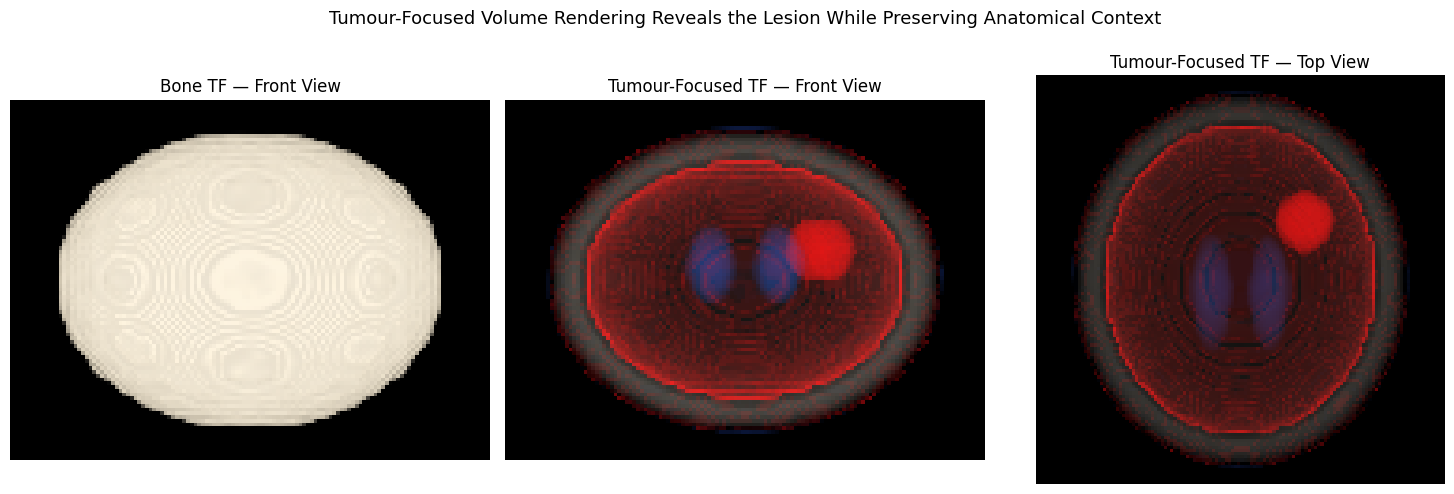

In [ ]:

bone_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (200,   (0, 0, 0), 0),
    (400,   (1, 0.95, 0.85), 0.3),
    (1500,  (1, 1, 1), 0.6)
])

# TODO 2: Design a tumour-focused transfer function
# Air and ordinary soft tissue: transparent
# CSF: faint blue
# Tumour-range intensities: red
# Bone: almost transparent

tumour_tf = make_tf([
    (-1000, (0, 0, 0),       0.00),  # Air
    (4,     (0, 0, 0),       0.00),  # Lower end of soft tissue
    (5,     (0.2, 0.4, 1.0), 0.015), # CSF begins
    (20,    (0.2, 0.4, 1.0), 0.015), # Faint blue CSF
    (30,    (0, 0, 0),       0.00),  # Suppress ordinary soft tissue
    (54,    (0, 0, 0),       0.00),
    (55,    (1.0, 0.05, 0.05), 0.08),# Tumour range starts
    (72,    (1.0, 0.05, 0.05), 0.08),# Red tumour
    (90,    (1.0, 0.05, 0.05), 0.08),
    (100,   (0, 0, 0),       0.00),  # Suppress other soft tissue
    (200,   (0, 0, 0),       0.00),
    (400,   (1.0, 0.95, 0.85), 0.005), # Bone: almost transparent
    (1500,  (1.0, 1.0, 1.0), 0.01)
])

# TODO 1 & 3: Render bone and tumour-focused views
bone_front, bone_alpha = render(vol, bone_tf, axis=1)
tumour_front, tumour_front_alpha = render(vol, tumour_tf, axis=1)
tumour_top, tumour_top_alpha = render(vol, tumour_tf, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

axes[0].imshow(np.clip(bone_front, 0, 1), origin="lower")
axes[0].set_title("Bone TF — Front View")

axes[1].imshow(np.clip(tumour_front, 0, 1), origin="lower")
axes[1].set_title("Tumour-Focused TF — Front View")

axes[2].imshow(np.clip(tumour_top, 0, 1), origin="lower")
axes[2].set_title("Tumour-Focused TF — Top View")

for ax in axes:
    ax.axis("off")

# TODO 4: Conclusion-style title
fig.suptitle(
    "Tumour-Focused Volume Rendering Reveals the Lesion "
    "While Preserving Anatomical Context",
    fontsize=13,
    y=1.02
)

plt.tight_layout()
plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_ : The faint red rim is caused by overlapping intensity ranges and partial-volume effects, which make some voxels near the skull have HU values similar to those of the tumour. This leads to false positives in the volume rendering. One technique to remove the rim is threshold-based segmentation followed by connected-component analysis (Slides 31–32), which isolates the tumour region and removes disconnected voxels near the skull. A transfer function alone cannot reliably distinguish the tumour from other tissues with similar HU values because it maps intensity values to colour and opacity without considering spatial connectivity or anatomical location.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_ Your final note here:

The CT analysis identified a suspected lesion near [insert the anatomical location from your three-plane MPR views], with an estimated volume ranging from [minimum volume] mL to [maximum volume] mL across the tested HU thresholds. I recommend opening the tumour-board meeting with the three-plane MPR view, because orthogonal slicing exposes internal anatomy and shows the lesion's position in axial, coronal and sagittal planes without the occlusion that can affect 3-D rendering. The threshold-based segmentation provides a volume estimate, but the range demonstrates that the measurement depends on the chosen threshold. The 3-D render helps visualize the lesion in context with surrounding structures, including the ventricles, when they are adequately visible. However, overlapping tissue intensities can cause false positives, and the transfer function alone cannot reliably distinguish tumour from other tissues with similar HU values.